# CS664 Assignment1 - Part2 - Wei Zhao

In [1]:
from hw1_helpers_russell import Environment, Agent, TraceAgent
import random
import matplotlib.pyplot as plt

In [25]:
def RandomAgentProgram(actions):
    """An agent that chooses an action at random, ignoring all percepts."""
    
    def program(percept):
            action = random.choice(actions)
            qty = random.randint(1, 25)
            return action, qty
        
    return program

In [26]:
def RandomTradingAgent():
    return Agent(RandomAgentProgram(['Buy', 'Sell', 'Hold']))

In [27]:
random.seed(1234)
print(RandomTradingAgent().program({'last_price': 200, 'current_price': 185, 'holding_shares': 115}))
print(RandomTradingAgent().program({'last_price': 160, 'current_price': 170, 'holding_shares': 100}))
print(RandomTradingAgent().program({'last_price': 160, 'current_price': 170, 'holding_shares': 150}))

"""
('Sell', 4)
('Buy', 3)
('Hold', 2)
"""

('Sell', 4)
('Buy', 3)
('Hold', 2)


"\n('Sell', 4)\n('Buy', 3)\n('Hold', 2)\n"

In [28]:
random.seed(7777)
print(RandomTradingAgent().program({'last_price': 200, 'current_price': 185, 'holding_shares': 115}))
print(RandomTradingAgent().program({'last_price': 160, 'current_price': 170, 'holding_shares': 100}))
print(RandomTradingAgent().program({'last_price': 160, 'current_price': 170, 'holding_shares': 150}))

"""
('Buy', 17)
('Sell', 15)
('Sell', 3)
"""

('Buy', 17)
('Sell', 15)
('Sell', 3)


"\n('Buy', 17)\n('Sell', 15)\n('Sell', 3)\n"

In [ ]:
def SmartAgentProgram(actions):
    """An agent that chooses an action based on the percept.
       Assume actions is the list ['Buy', 'Sell', 'Hold'] """

    def program(percept):
        #taken inspiration from AIMA_02 cell 2 and 22 and tweaked
        desired = random.randint(1,25)
        last_price = percept['last_price']
        current_price = percept['current_price']
        holding_shares = percept['holding_shares']

        if current_price < last_price:
            return 'Buy', desired
        elif current_price > last_price:
            if desired < holding_shares:
                sell_qty = desired
            else:
                sell_qty = holding_shares
            return 'Sell', sell_qty
        else:
            return 'Hold', holding_shares
        
    return program

In [14]:
def SmartTradingAgent():
    return Agent(SmartAgentProgram(['Buy', 'Sell', 'Hold']))

In [29]:
random.seed(1234)
print(SmartTradingAgent().program({'last_price': 200, 'current_price': 185, 'holding_shares': 115}))
print(SmartTradingAgent().program({'last_price': 160, 'current_price': 170, 'holding_shares': 100}))
print(SmartTradingAgent().program({'last_price': 160, 'current_price': 160, 'holding_shares': 150}))

"""
('Buy', 25)
('Sell', 15)
('Hold', 150)
"""

('Buy', 25)
('Sell', 15)
('Hold', 150)


"\n('Buy', 25)\n('Sell', 15)\n('Hold', 150)\n"

In [ ]:
class TradingEnvironment(Environment):
    
    def __init__(self):
        super().__init__()
        self.shares = 100
        self.last_price, self.current_price = 200, 200
        self.portfolio_history = [self.shares * self.current_price]

    def percept(self, agent):
        return {'last_price': self.last_price,
                'current_price': self.current_price,
                'holding_shares' : self.shares}

    def execute_action(self, agent, action):
        todo, qty = action
        
        if todo == 'Buy':
            self.shares += qty
            agent.performance = self.shares * self.current_price
            #taken inspiration from the append from HW1 and AIMA_01 for 
        elif todo == 'Sell':
            self.shares -= qty
            agent.performance = self.shares * self.current_price
        else:
            pass

        self.portfolio_history.append(agent.performance)
        self.last_price = self.current_price
        self.current_price = self.current_price + random.randint(-20,20)
        

In [32]:
# Test code for random one is given. Use your random seed.

random.seed(6449)

agent1 = RandomTradingAgent()
agent1 = TraceAgent(agent1)
environment1 = TradingEnvironment()

environment1.add_thing(agent1)
agent1.performance = 100 * 200

environment1.run(20)

print('Agent score = {}'.format(agent1.performance))

print(environment1.portfolio_history)


 <Agent> perceives {'last_price': 200, 'current_price': 200, 'holding_shares': 100} and does ('Sell', 20)
 <Agent> perceives {'last_price': 200, 'current_price': 211, 'holding_shares': 80} and does ('Hold', 17)
 <Agent> perceives {'last_price': 211, 'current_price': 215, 'holding_shares': 80} and does ('Hold', 10)
 <Agent> perceives {'last_price': 215, 'current_price': 198, 'holding_shares': 80} and does ('Buy', 9)
 <Agent> perceives {'last_price': 198, 'current_price': 217, 'holding_shares': 89} and does ('Buy', 16)
 <Agent> perceives {'last_price': 217, 'current_price': 229, 'holding_shares': 105} and does ('Hold', 4)
 <Agent> perceives {'last_price': 229, 'current_price': 248, 'holding_shares': 105} and does ('Sell', 3)
 <Agent> perceives {'last_price': 248, 'current_price': 266, 'holding_shares': 102} and does ('Buy', 11)
 <Agent> perceives {'last_price': 266, 'current_price': 258, 'holding_shares': 113} and does ('Buy', 19)
 <Agent> perceives {'last_price': 258, 'current_price': 2

In [42]:
random.seed(6449)

agent2 = SmartTradingAgent()
agent2 = TraceAgent(agent2)
environment2 = TradingEnvironment()

environment2.add_thing(agent2)
agent2.performance = 100 * 200

environment2.run(20)

print('Agent score = {}'.format(agent2.performance))

print(environment2.portfolio_history)





 <Agent> perceives {'last_price': 200, 'current_price': 200, 'holding_shares': 100} and does ('Hold', 100)
 <Agent> perceives {'last_price': 200, 'current_price': 219, 'holding_shares': 100} and does ('Sell', 21)
 <Agent> perceives {'last_price': 219, 'current_price': 230, 'holding_shares': 79} and does ('Sell', 19)
 <Agent> perceives {'last_price': 230, 'current_price': 243, 'holding_shares': 60} and does ('Sell', 13)
 <Agent> perceives {'last_price': 243, 'current_price': 257, 'holding_shares': 47} and does ('Sell', 10)
 <Agent> perceives {'last_price': 257, 'current_price': 240, 'holding_shares': 37} and does ('Buy', 2)
 <Agent> perceives {'last_price': 240, 'current_price': 236, 'holding_shares': 39} and does ('Buy', 20)
 <Agent> perceives {'last_price': 236, 'current_price': 221, 'holding_shares': 59} and does ('Buy', 16)
 <Agent> perceives {'last_price': 221, 'current_price': 233, 'holding_shares': 75} and does ('Sell', 20)
 <Agent> perceives {'last_price': 233, 'current_price': 

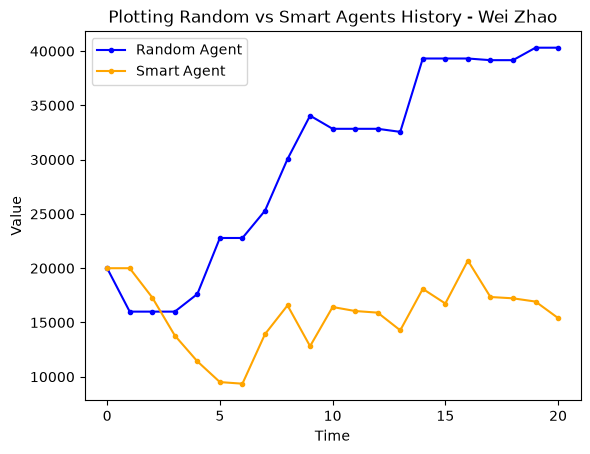

In [43]:
x = range(len(environment1.portfolio_history))

# Plot the first set of data
plt.plot(x, environment1.portfolio_history, label='Random Agent', color='blue', marker='.')

# Plot the second set of data
plt.plot(x, environment2.portfolio_history, label='Smart Agent', color='orange', marker='.')

plt.title('Plotting Random vs Smart Agents History - Wei Zhao')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()         
plt.locator_params(axis='both', integer=True)

plt.show()